# Genomic-only performance: with and without mutation supervision

Compare two prediction CSVs for the same cohort and held-out fold. C-index is higher-is-better; survival NLL is lower-is-better. Observed-event bin accuracy excludes censored patients. Mutation BCE is excluded from the survival NLL comparison.

Set `CANCER` and `FOLD` below. The notebook reads files directly from `result/`, without retraining. Run both experiments with identical survival-bin definitions, splits, and hyperparameters. Matching patient IDs, labels and outcomes are checked; two CSVs alone cannot independently verify the original bin boundaries or training settings.


In [50]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "utils/metrics_utils.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from utils.metrics_utils import concordance_index

CANCER = "lgg"  # Change to "gbm" for GBM results.
MODEL = "resmlp"
FILENAME = f"filter_normalized_zscore_{CANCER}.csv"
FOLD = 3
RESULT_DIR = ROOT / "result"
WITHOUT_FILE = RESULT_DIR / f"split_{MODEL}_{FILENAME}_{FOLD}_without_mutation_predictions.csv"
WITH_FILE = RESULT_DIR / f"split_{MODEL}_{FILENAME}_{FOLD}_mutation_predictions.csv"
EXPORT_DIR = ROOT / "result/comparisons/genomic_mutation" / MODEL / FILENAME / f"fold_{FOLD}"

def compare(without_file, with_file):
    files = [{FOLD: Path(path)} for path in (without_file, with_file)]
    for path in (without_file, with_file):
        if not Path(path).is_file():
            raise FileNotFoundError(f"Prediction file not found: {path}")
    records, seen = [], [set(), set()]
    for fold in sorted(files[0]):
        frames = [pd.read_csv(paths[fold]).sort_values("case_id").reset_index(drop=True) for paths in files]
        for i, (mode, frame) in enumerate(zip(("without_mutation", "with_mutation"), frames)):
            if frame.case_id.isna().any() or frame.case_id.duplicated().any() or seen[i] & set(frame.case_id):
                raise ValueError("Require unique held-out patients, with no overlap between folds.")
            seen[i].update(frame.case_id)
        columns = ["case_id", "label", "event_time", "censorship"]
        if not frames[0][columns].equals(frames[1][columns]):
            raise ValueError(f"Fold {fold}: patients, outcomes or time bins differ.")
        for mode, frame in zip(("without_mutation", "with_mutation"), frames):
            hazard_cols = sorted((c for c in frame if c.startswith("hazard_")),
                                 key=lambda c: int(c.rsplit("_", 1)[1]))
            if not hazard_cols:
                raise ValueError("Use survival NLL runs with saved hazard columns.")
            hazards = frame[hazard_cols].to_numpy(float)
            labels = frame.label.to_numpy(float)
            censor = frame.censorship.to_numpy(float)
            if not np.isfinite(hazards).all() or ((hazards < 0) | (hazards > 1)).any():
                raise ValueError("Hazards must be finite probabilities.")
            if not np.isfinite(labels).all() or not (labels == labels.astype(int)).all():
                raise ValueError("Invalid survival-bin labels.")
            labels = labels.astype(int)
            if ((labels < 0) | (labels >= len(hazard_cols))).any() or not np.isin(censor, [0, 1]).all():
                raise ValueError("Invalid interval or censoring labels.")
            hazards = np.clip(hazards, 1e-12, 1-1e-12)
            log_s = np.log1p(-hazards).cumsum(axis=1)
            before = np.column_stack([np.zeros(len(frame)), log_s[:, :-1]])
            rows = np.arange(len(frame))
            event_log = before[rows, labels] + np.log(hazards[rows, labels])
            nll = -((1-censor)*event_log + censor*log_s[rows, labels]).mean()
            observed = censor == 0
            records.append(dict(experiment=mode, fold=fold, patients=len(frame),
                val_cindex=concordance_index(frame.event_time, censor, frame.risk),
                val_survival_nll=nll,
                observed_bin_accuracy=(frame.prediction.to_numpy()[observed] == labels[observed]).mean()
                if observed.any() else np.nan))
    return pd.DataFrame(records)


## Selected prediction files

- `split_resmlp_filter_normalized_zscore_lgg.csv_0_without_mutation_predictions.csv`
- `split_resmlp_filter_normalized_zscore_lgg.csv_0_mutation_predictions.csv`

These names follow the `CANCER`, `MODEL`, and `FOLD` settings. Both files may reside in the same result folder because their filenames differ.


In [51]:
print("Without mutation:", WITHOUT_FILE)
print("With mutation:", WITH_FILE)
folds = compare(WITHOUT_FILE, WITH_FILE)
print(f"Dataset: {CANCER.upper()} | Model: {MODEL} | Validation fold: {FOLD}")
display(folds.round(4))


Without mutation: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/split_resmlp_filter_normalized_zscore_lgg.csv_3_without_mutation_predictions.csv
With mutation: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/split_resmlp_filter_normalized_zscore_lgg.csv_3_mutation_predictions.csv
Dataset: LGG | Model: resmlp | Validation fold: 3


,experiment,fold,patients,val_cindex,val_survival_nll,observed_bin_accuracy
0,without_mutation,3,103,0.8346,0.8925,0.30
1,with_mutation,3,103,0.8624,0.8303,0.45


In [52]:
summary = folds.set_index("experiment")[["patients", "val_cindex", "val_survival_nll", "observed_bin_accuracy"]]
display(summary.round(4))
metrics = ["val_cindex", "val_survival_nll", "observed_bin_accuracy"]
differences = (summary.loc["with_mutation", metrics] - summary.loc["without_mutation", metrics]).to_frame("with_minus_without")
print("Positive C-index/accuracy difference favors mutation; negative NLL difference favors mutation.")
display(differences.round(4))


,patients,val_cindex,val_survival_nll,observed_bin_accuracy
experiment,,,,
without_mutation,103,0.8346,0.8925,0.30
with_mutation,103,0.8624,0.8303,0.45


Positive C-index/accuracy difference favors mutation; negative NLL difference favors mutation.


,with_minus_without
val_cindex,0.0278
val_survival_nll,-0.0622
observed_bin_accuracy,0.1500


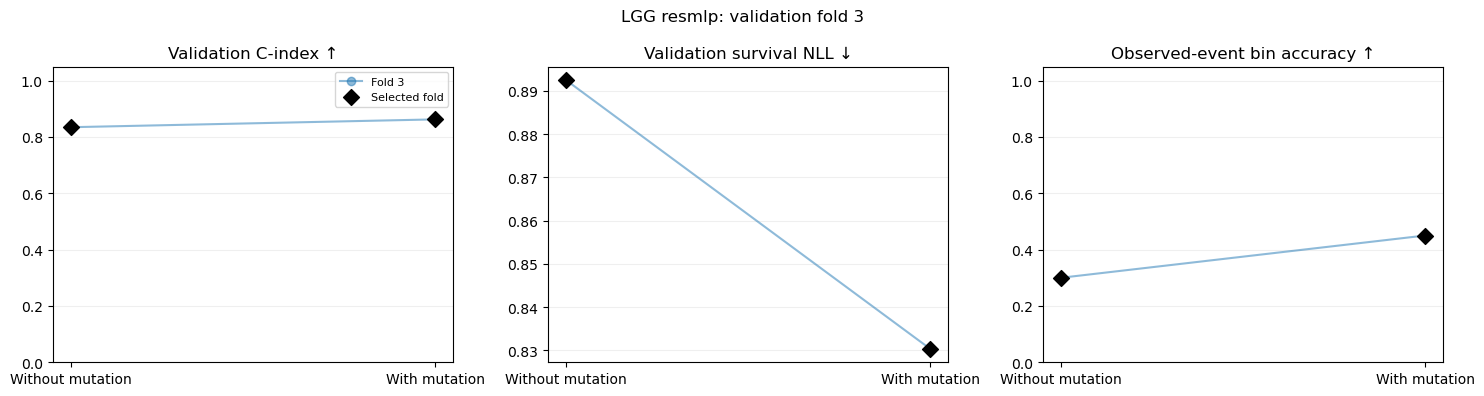

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = ["without_mutation", "with_mutation"]
for ax, metric, title in zip(
    axes,
    ["val_cindex", "val_survival_nll", "observed_bin_accuracy"],
    ["Validation C-index ↑", "Validation survival NLL ↓", "Observed-event bin accuracy ↑"],
):
    values = folds.pivot(index="fold", columns="experiment", values=metric)[order]
    for fold, row in values.iterrows():
        ax.plot([0, 1], row.to_numpy(), "o-", alpha=0.5, label=f"Fold {fold}")
    ax.scatter([0, 1], values.mean().to_numpy(), color="black", marker="D", s=65,
               label="Selected fold", zorder=3)
    ax.set(xticks=[0, 1], xticklabels=["Without mutation", "With mutation"], title=title)
    ax.grid(axis="y", alpha=0.2)
    if metric != "val_survival_nll":
        ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8)
fig.suptitle(f"{CANCER.upper()} {MODEL}: validation fold {FOLD}")
fig.tight_layout()
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(EXPORT_DIR / "validation_comparison_LGG.png", dpi=300, bbox_inches="tight")
fig.savefig(EXPORT_DIR / "validation_comparison_LGG.pdf", bbox_inches="tight")
plt.show()


In [54]:
folds.to_csv(EXPORT_DIR / "per_fold_comparison.csv", index=False)
summary.to_csv(EXPORT_DIR / "performance_comparison.csv")
differences.to_csv(EXPORT_DIR / "performance_differences.csv")
print(f"Tables and presentation figures saved to: {EXPORT_DIR}")


Tables and presentation figures saved to: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/genomic_mutation/resmlp/filter_normalized_zscore_lgg.csv/fold_3


## GBM: with versus without mutation supervision

Compare the **GBM-trained** models using the two saved GBM prediction files for the selected `FOLD`. This is a within-GBM comparison, separate from the LGG-trained model external test below. Patient IDs, reference bins, and survival outcomes must match between experiments.


Without mutation: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/split_resmlp_filter_normalized_zscore_gbm.csv_2_without_mutation_predictions.csv
With mutation: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/split_resmlp_filter_normalized_zscore_gbm.csv_2_mutation_predictions.csv
GBM-trained resmlp: GBM validation fold 2


,patients,val_cindex,val_survival_nll,observed_bin_accuracy
experiment,,,,
without_mutation,52,0.5871,1.8719,0.3947
with_mutation,52,0.5826,1.6648,0.4474


,with_minus_without
val_cindex,-0.0045
val_survival_nll,-0.2071
observed_bin_accuracy,0.0526


Positive C-index/accuracy difference favors mutation; negative NLL difference favors mutation.


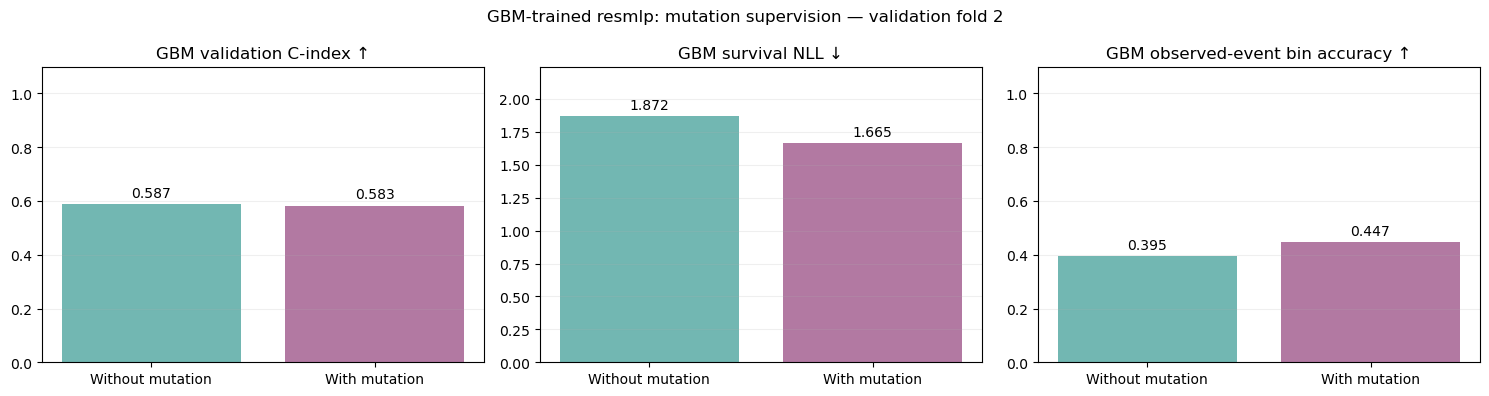

GBM tables and plots saved to: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/genomic_mutation/resmlp/filter_normalized_zscore_gbm.csv/fold_2


In [55]:
FOLD = 2
GBM_FILENAME = "filter_normalized_zscore_gbm.csv"
GBM_WITHOUT_FILE = ROOT / "result" / f"split_{MODEL}_{GBM_FILENAME}_{FOLD}_without_mutation_predictions.csv"
GBM_WITH_FILE = ROOT / "result" / f"split_{MODEL}_{GBM_FILENAME}_{FOLD}_mutation_predictions.csv"
GBM_EXPORT_DIR = ROOT / "result/comparisons/genomic_mutation" / MODEL / GBM_FILENAME / f"fold_{FOLD}"

print("Without mutation:", GBM_WITHOUT_FILE)
print("With mutation:", GBM_WITH_FILE)
gbm_folds = compare(GBM_WITHOUT_FILE, GBM_WITH_FILE)
gbm_summary = gbm_folds.set_index("experiment")[["patients", "val_cindex", "val_survival_nll", "observed_bin_accuracy"]]
print(f"GBM-trained {MODEL}: GBM validation fold {FOLD}")
display(gbm_summary.round(4))
comparison_metrics = ["val_cindex", "val_survival_nll", "observed_bin_accuracy"]
gbm_differences = (gbm_summary.loc["with_mutation", comparison_metrics]
                   - gbm_summary.loc["without_mutation", comparison_metrics]).to_frame("with_minus_without")
display(gbm_differences.round(4))
print("Positive C-index/accuracy difference favors mutation; negative NLL difference favors mutation.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, comparison_metrics,
        ["GBM validation C-index ↑", "GBM survival NLL ↓", "GBM observed-event bin accuracy ↑"]):
    values = gbm_summary.loc[["without_mutation", "with_mutation"], metric]
    bars = ax.bar(["Without mutation", "With mutation"], values, color=["#72b7b2", "#b279a2"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)
    if metric != "val_survival_nll":
        ax.set_ylim(0, 1.1)
    else:
        ax.margins(y=0.2)
fig.suptitle(f"GBM-trained {MODEL}: mutation supervision — validation fold {FOLD}")
fig.tight_layout()
GBM_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GBM_EXPORT_DIR / "validation_comparison_GBM.png", dpi=300, bbox_inches="tight")
fig.savefig(GBM_EXPORT_DIR / "validation_comparison_GBM.pdf", bbox_inches="tight")
plt.show()
gbm_folds.to_csv(GBM_EXPORT_DIR / "per_fold_comparison.csv", index=False)
gbm_summary.to_csv(GBM_EXPORT_DIR / "performance_comparison.csv")
gbm_differences.to_csv(GBM_EXPORT_DIR / "performance_differences.csv")
print(f"GBM tables and plots saved to: {GBM_EXPORT_DIR}")


## Training performance: LGG and GBM, with and without mutation

Training C-index and loss are measured during each training epoch (dropout active and weights changing). They are not a final fixed-model evaluation. Compare **survival-only loss** between experiments; total loss includes an extra mutation term in the mutation-enabled run. `train_mutation_loss` is its weighted contribution to total loss.

New training runs save `training_history_fold_<fold>_mutation.csv` and `training_history_fold_<fold>_without_mutation.csv`. Untagged old histories cannot reliably identify both experiments and are not used. Rerun both experiments to create missing histories. This section uses the selected `FOLD` for both cohorts. Adjust the two result roots if experiments were saved separately.


In [56]:
TRAINING_WITH_ROOT = ROOT / "result"
TRAINING_WITHOUT_ROOT = ROOT / "result"
training_records = []
training_histories = {}
for cohort in ("lgg", "gbm"):
    filename = f"filter_normalized_zscore_{cohort}.csv"
    paths = {
        "without_mutation": TRAINING_WITHOUT_ROOT / MODEL / filename / f"training_history_fold_{FOLD}_without_mutation.csv",
        "with_mutation": TRAINING_WITH_ROOT / MODEL / filename / f"training_history_fold_{FOLD}_mutation.csv",
    }
    missing = [str(path) for path in paths.values() if not path.exists()]
    if missing:
        print(f"{cohort.upper()}: training comparison unavailable. Rerun both experiments or correct paths:")
        print("\n".join(missing))
        continue
    for mode, path in paths.items():
        history = pd.read_csv(path)
        required = {"train_cindex", "train_loss", "train_survival_loss", "train_mutation_loss"}
        if history.empty or not required.issubset(history):
            raise ValueError(f"Missing training metrics in {path}; rerun with updated logging.")
        history["epoch"] = np.arange(1, len(history) + 1)
        training_histories[(cohort, mode)] = history
        last = history.iloc[-1]
        training_records.append(dict(cohort=cohort.upper(), experiment=mode, fold=FOLD,
            epochs=len(history), final_train_cindex=last.train_cindex,
            final_survival_loss=last.train_survival_loss,
            final_mutation_loss=last.train_mutation_loss, final_total_loss=last.train_loss))
    cohort_export = ROOT / "result/comparisons/genomic_mutation" / MODEL / filename / f"fold_{FOLD}"
    cohort_export.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, title in zip(axes,
            ["train_cindex", "train_survival_loss", "train_loss"],
            ["Training C-index ↑", "Training survival loss ↓", "Training total loss (different objectives)"]):
        for mode in paths:
            history = training_histories[(cohort, mode)]
            ax.plot(history.epoch, history[metric], label=mode.replace("_", " "))
        ax.set(xlabel="Epoch", title=title)
        ax.grid(alpha=0.2)
        ax.legend()
    fig.suptitle(f"{cohort.upper()} {MODEL}: training performance — fold {FOLD}")
    fig.tight_layout()
    fig.savefig(cohort_export / "training_comparison.png", dpi=300, bbox_inches="tight")
    fig.savefig(cohort_export / "training_comparison.pdf", bbox_inches="tight")
    plt.show()
    for mode in paths:
        training_histories[(cohort, mode)].to_csv(cohort_export / f"training_history_{mode}.csv", index=False)
if training_records:
    training_summary = pd.DataFrame(training_records)
    display(training_summary.round(4))
    training_export = ROOT / "result/comparisons/genomic_mutation" / MODEL
    training_export.mkdir(parents=True, exist_ok=True)
    training_summary.to_csv(training_export / f"training_comparison_fold_{FOLD}.csv", index=False)


LGG: training comparison unavailable. Rerun both experiments or correct paths:
/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/resmlp/filter_normalized_zscore_lgg.csv/training_history_fold_2_without_mutation.csv
/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/resmlp/filter_normalized_zscore_lgg.csv/training_history_fold_2_mutation.csv
GBM: training comparison unavailable. Rerun both experiments or correct paths:
/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/resmlp/filter_normalized_zscore_gbm.csv/training_history_fold_2_without_mutation.csv


## External test: LGG-trained ResMLP → GBM patients

This evaluates GBM expression using frozen LGG model weights, LGG training scaler, original gene order, and LGG survival-bin boundaries. No GBM training, scaling fit, or bin fit is performed. Missing source genes or overlapping training patients stop evaluation.

Rerun both LGG experiments with the updated training code to save `genomic_fold_<fold>_<mode>_bundle.pt`. Existing generic `best_model_fold_<fold>.pt` files lack reliable preprocessing/provenance and cannot be used here. Set the two bundle paths below to the LGG runs you want to test. A selected-fold external test is descriptive and does not establish generalization across folds.

Expression matrices must use compatible normalization upstream; preserving the LGG training scaler alone cannot correct incompatible upstream processing. GBM mutation labels are not required as model inputs.


In [57]:
from utils.genomic_external import evaluate_external

LGG_MODEL_DIR = ROOT / "result/resmlp/filter_normalized_zscore_lgg.csv"
LGG_WITHOUT_BUNDLE = LGG_MODEL_DIR / f"genomic_fold_{FOLD}_without_mutation_bundle.pt"
LGG_WITH_BUNDLE = LGG_MODEL_DIR / f"genomic_fold_{FOLD}_mutation_bundle.pt"
# If training used separate result folders, adjust these two paths accordingly.
# Use the full expression matrix: the filtered GBM file lacks some LGG training genes.
GBM_EXPRESSION = ROOT / "dataset_csv/genomic_data/normalized_zscore_gbm.csv"
GBM_CLINICAL = ROOT / "dataset_csv/metadata/clinical_gbm.csv"
EXTERNAL_DIR = ROOT / "result/comparisons/genomic_mutation/lgg_to_gbm" / f"fold_{FOLD}"

bundles = {"without_mutation": LGG_WITHOUT_BUNDLE, "with_mutation": LGG_WITH_BUNDLE}
missing = [str(path) for path in bundles.values() if not path.exists()]
if missing:
    print("External GBM test was not run. Rerun LGG training to save these bundles, or correct their paths:")
    print("\n".join(missing))
else:
    import torch
    source = [torch.load(path, map_location="cpu", weights_only=True) for path in bundles.values()]
    if any("lgg" not in item["source_file"].lower() or "gbm" in item["source_file"].lower() for item in source):
        raise ValueError("Both bundles must be from LGG-only training.")
    if source[0]["fold"] != source[1]["fold"] or set(source[0]["training_patient_ids"]) != set(source[1]["training_patient_ids"]):
        raise ValueError("The LGG experiments must use the same training patients and fold.")
    for field in ("feature_cols", "mean", "std", "bin_edges"):
        if source[0][field] != source[1][field]:
            raise ValueError(f"LGG source preprocessing differs: {field}")
    if source[0]["mutation_genes"] or not source[1]["mutation_genes"]:
        raise ValueError("Check the with/without mutation bundle paths.")
    external = pd.DataFrame([
        {"experiment": mode, **evaluate_external(path, GBM_EXPRESSION, GBM_CLINICAL,
             EXTERNAL_DIR / f"lgg_model_gbm_{mode}_predictions.csv")}
        for mode, path in bundles.items()
    ]).set_index("experiment")
    display(external.round(4))
    external.to_csv(EXTERNAL_DIR / "external_gbm_comparison.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, metric, title in zip(axes, ["external_cindex", "external_survival_nll"],
                               ["GBM C-index ↑", "GBM survival NLL ↓"]):
        external[metric].plot.bar(ax=ax, color=["#72b7b2", "#b279a2"], rot=0)
        ax.set_title(title)
        ax.set_xlabel("")
    fig.suptitle(f"LGG-trained ResMLP tested on GBM — source fold {FOLD}")
    fig.tight_layout()
    fig.savefig(EXTERNAL_DIR / "external_gbm_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()


External GBM test was not run. Rerun LGG training to save these bundles, or correct their paths:
/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/resmlp/filter_normalized_zscore_lgg.csv/genomic_fold_2_without_mutation_bundle.pt
/home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/resmlp/filter_normalized_zscore_lgg.csv/genomic_fold_2_mutation_bundle.pt
